# Support Ticket Classification & Prioritization

## Data Collection & Exploratory Data Analysis (EDA)

**Project:** FUTURE_ML_02

**Dataset:** IT Service Ticket Classification

**Objective:** Analyze IT support tickets and prepare the dataset for automatic ticket category classification.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"D:\FUTURE_ML_02\data\raw\IT Service Ticket Classification dataset.csv")

print("Dataset loaded successfully!")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset loaded successfully!
Number of Rows: 47837
Number of Columns: 2


In [2]:
display(df.head(10))

,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous
5,mail please dear looks blacklisted receiving m...,Miscellaneous
6,prod servers tunneling prod tunneling va la tu...,Hardware
7,access request dear modules report report cost...,HR Support
8,reset passwords for our client and passwords c...,Access
9,direct reports missing time please action repo...,HR Support


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Document     47837 non-null  str  
 1   Topic_group  47837 non-null  str  
dtypes: str(2)
memory usage: 14.5 MB


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nEmpty documents:", (df["Document"].str.strip() == "").sum())

print("\nEmpty category labels:", (df["Topic_group"].str.strip() == "").sum())

Missing values:
Document       0
Topic_group    0
dtype: int64

Duplicate rows: 0

Empty documents: 0

Empty category labels: 0


In [5]:
print("Unique ticket categories:", df["Topic_group"].nunique())

print("\nCategory names:")
print(df["Topic_group"].unique())

print("\nNumber of tickets per category:")
print(df["Topic_group"].value_counts())

Unique ticket categories: 8

Category names:
<ArrowStringArray>
[             'Hardware',                'Access',         'Miscellaneous',
            'HR Support',              'Purchase', 'Administrative rights',
               'Storage',      'Internal Project']
Length: 8, dtype: str

Number of tickets per category:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64


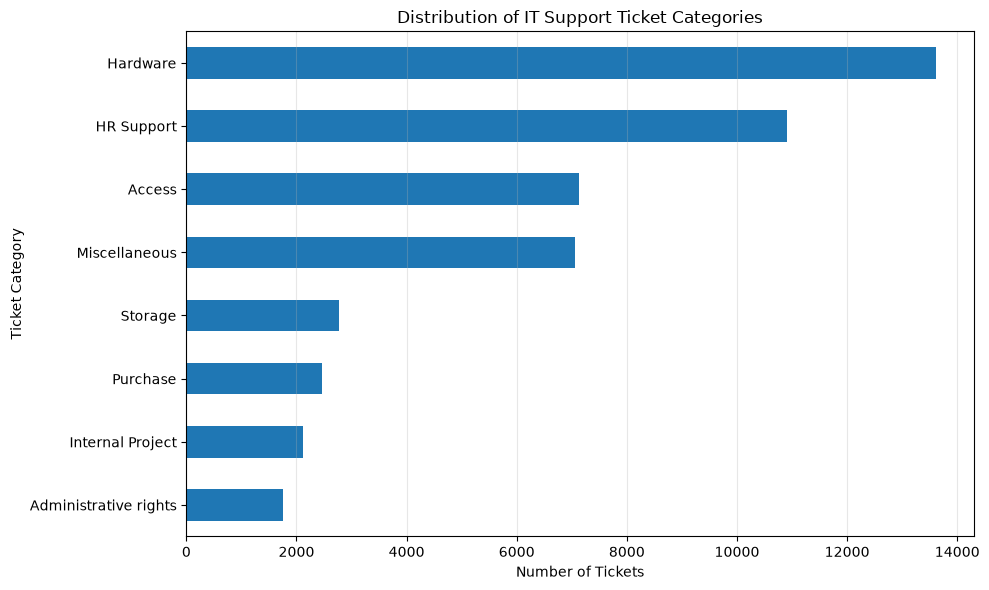

In [6]:
import matplotlib.pyplot as plt

category_counts = df["Topic_group"].value_counts().sort_values()

plt.figure(figsize=(10, 6))
category_counts.plot(kind="barh")

plt.title("Distribution of IT Support Ticket Categories")
plt.xlabel("Number of Tickets")
plt.ylabel("Ticket Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
category_percentage = (
    df["Topic_group"].value_counts(normalize=True) * 100
).round(2)

category_summary = pd.DataFrame({
    "Ticket Count": df["Topic_group"].value_counts(),
    "Percentage": category_percentage
})

display(category_summary)

,Ticket Count,Percentage
Topic_group,,
Hardware,13617,28.47
HR Support,10915,22.82
Access,7125,14.89
Miscellaneous,7060,14.76
Storage,2777,5.81
Purchase,2464,5.15
Internal Project,2119,4.43
Administrative rights,1760,3.68


In [8]:
df["text_length"] = df["Document"].apply(lambda x: len(x.split()))

print("Text Length Statistics:")
display(df["text_length"].describe())

Text Length Statistics:


count    47837.000000
mean        43.597341
std         56.736800
min          2.000000
25%         17.000000
50%         26.000000
75%         46.000000
max        981.000000
Name: text_length, dtype: float64

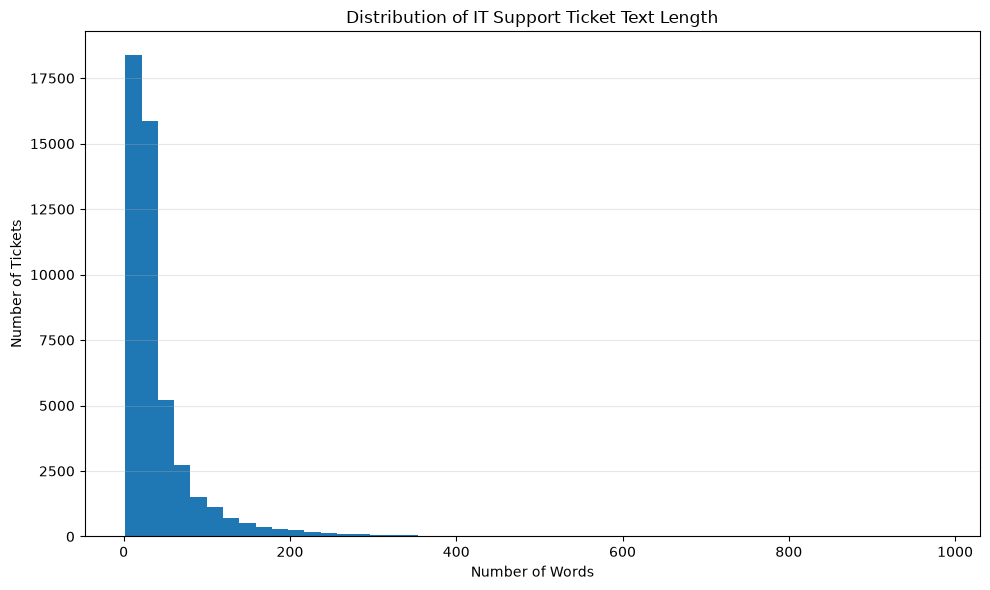

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(df["text_length"], bins=50)

plt.title("Distribution of IT Support Ticket Text Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Tickets")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:
for i in range(10):
    print(f"\nTicket {i + 1}")
    print("Category:", df.loc[i, "Topic_group"])
    print("Document:", df.loc[i, "Document"])
    print("-" * 100)


Ticket 1
Category: Hardware
Document: connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead
----------------------------------------------------------------------------------------------------

Ticket 2
Category: Access
Document: work experience user work experience user hi work experience student coming next his name much appreciate him duration thank
----------------------------------------------------------------------------------------------------

Ticket 3
Category: Hardware
Document: requesting for meeting requesting meeting hi please help follow equipments cable pc cord plug
----------------------------------------------------------------------------------------------------

Ticket 4
Category: Access
Document: reset passwords for external accounts re expire days hi ask help update passwords colleagues thank pm expire days importance high hi received about expiration please kindly help prolongation best regards pm expire 

In [11]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words="english", max_features=20)

word_matrix = vectorizer.fit_transform(df["Document"])

word_counts = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_matrix.sum(axis=0).A1
}).sort_values(by="Frequency", ascending=False)

display(word_counts)

,Word,Frequency
12,pm,28902
8,hi,28498
13,regards,27212
15,thank,24962
6,hello,23025
16,thanks,19852
14,sent,14717
11,kind,13241
0,access,13153
7,help,11173


In [12]:
vectorizer = CountVectorizer(stop_words="english")

word_matrix = vectorizer.fit_transform(df["Document"])

print("Total unique words:", len(vectorizer.get_feature_names_out()))
print("Document-Term Matrix Shape:", word_matrix.shape)



Total unique words: 12049
Document-Term Matrix Shape: (47837, 12049)


In [13]:
for category in df["Topic_group"].unique():
    print("\nCategory:", category)

    category_text = df.loc[
        df["Topic_group"] == category, "Document"
    ]

    category_vectorizer = CountVectorizer(
        stop_words="english",
        max_features=10
    )

    category_matrix = category_vectorizer.fit_transform(category_text)

    word_frequency = pd.DataFrame({
        "Word": category_vectorizer.get_feature_names_out(),
        "Frequency": category_matrix.sum(axis=0).A1
    }).sort_values(by="Frequency", ascending=False)

    display(word_frequency)


Category: Hardware


,Word,Frequency
2,hi,9143
6,regards,9038
5,pm,7903
1,hello,7666
8,thank,7551
7,sent,6741
9,thanks,6067
0,access,4773
3,issue,4240
4,kind,4082



Category: Access


,Word,Frequency
2,confluence,4587
5,pm,4401
4,hi,4001
6,regards,3440
3,hello,3182
8,thanks,3150
7,thank,3097
1,card,2656
9,user,2654
0,access,2643



Category: Miscellaneous


...

,Word,Frequency
9,upgrade,2745
4,regards,1017
0,hello,972
8,update,935
2,issues,933
6,thank,869
1,hi,841
5,sent,832
3,kb,578
7,thanks,559



Category: Storage


,Word,Frequency
4,mailbox,2445
1,folder,1953
0,access,1758
5,pm,1636
9,wants,1531
7,thank,1319
3,hi,1315
6,regards,1195
2,hello,1124
8,thanks,967



Category: Internal Project


,Word,Frequency
0,code,3346
4,pm,1903
3,hi,1804
9,thanks,1205
6,regards,1196
8,thank,1194
7,setup,1147
5,project,1115
1,codes,1066
2,hello,854


In [14]:
for category in df["Topic_group"].unique():
    category_text = df.loc[df["Topic_group"] == category, "Document"]

    category_vectorizer = CountVectorizer(
        stop_words="english",
        max_features=10
    )

    category_matrix = category_vectorizer.fit_transform(category_text)

    word_frequency = pd.Series(
        category_matrix.sum(axis=0).A1,
        index=category_vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

    print(f"\n{category}:")
    print(word_frequency.to_dict())


Hardware:
{'hi': 9143, 'regards': 9038, 'pm': 7903, 'hello': 7666, 'thank': 7551, 'sent': 6741, 'thanks': 6067, 'access': 4773, 'issue': 4240, 'kind': 4082}

Access:
{'confluence': 4587, 'pm': 4401, 'hi': 4001, 'regards': 3440, 'hello': 3182, 'thanks': 3150, 'thank': 3097, 'card': 2656, 'user': 2654, 'access': 2643}

Miscellaneous:
{'hi': 4660, 'pm': 4605, 'change': 4390, 'regards': 4116, 'thank': 3866, 'hello': 3405, 'thanks': 3264, 'add': 3197, 'sent': 2297, 'kind': 1920}

HR Support:
{'pm': 6477, 'thank': 6192, 'hi': 6092, 'leaver': 5646, 'regards': 5386, 'hello': 5383, 'error': 4778, 'form': 4570, 'starter': 4476, 'leave': 4215}

Purchase:
{'purchase': 3792, 'po': 3764, 'administrator': 2112, 'log': 1943, 'regards': 1824, 'order': 1823, 'receive': 1660, 'kind': 1654, 'dear': 1640, 'purchased': 1639}

Administrative rights:
{'upgrade': 2745, 'regards': 1017, 'hello': 972, 'update': 935, 'issues': 933, 'thank': 869, 'hi': 841, 'sent': 832, 'kb': 578, 'thanks': 559}

Storage:
{'mailb

In [15]:
short_tickets = df[df["text_length"] <= 3]

print("Tickets containing 3 or fewer words:", len(short_tickets))

display(short_tickets[["Document", "Topic_group", "text_length"]].head(15))

Tickets containing 3 or fewer words: 49


,Document,Topic_group,text_length
561,new starter please,HR Support,3
1203,new starter starter,HR Support,3
2006,remove restrictions restrictions,HR Support,3
3069,windows install install,Administrative rights,3
3246,allocate for assign,Hardware,3
3888,confluence account confluence,Access,3
4215,open si,Hardware,2
4247,cable cable provided,Hardware,3
4635,account developer,Access,2
4829,monitor monitor monitor,Hardware,3


In [16]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["cleaned_text"] = df["Document"].apply(clean_text)

display(df[["Document", "cleaned_text", "Topic_group"]].head(10))

,Document,cleaned_text,Topic_group
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...,Miscellaneous
5,mail please dear looks blacklisted receiving m...,mail please dear looks blacklisted receiving m...,Miscellaneous
6,prod servers tunneling prod tunneling va la tu...,prod servers tunneling prod tunneling va la tu...,Hardware
7,access request dear modules report report cost...,access request dear modules report report cost...,HR Support
8,reset passwords for our client and passwords c...,reset passwords for our client and passwords c...,Access
9,direct reports missing time please action repo...,direct reports missing time please action repo...,HR Support


In [17]:
print("Missing cleaned documents:", df["cleaned_text"].isnull().sum())

print("Empty cleaned documents:", (df["cleaned_text"].str.strip() == "").sum())

print("Total records:", len(df))

print("Unique cleaned documents:", df["cleaned_text"].nunique())

Missing cleaned documents: 0
Empty cleaned documents: 0
Total records: 47837
Unique cleaned documents: 47837


In [18]:
X = df["cleaned_text"]
y = df["Topic_group"]

print("Input features shape:", X.shape)
print("Target labels shape:", y.shape)

print("\nInput feature example:")
print(X.iloc[0])

print("\nTarget label example:")
print(y.iloc[0])

Input features shape: (47837,)
Target labels shape: (47837,)

Input feature example:
connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead

Target label example:
Hardware


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (38269,)
Testing data shape: (9568,)

Training labels shape: (38269,)
Testing labels shape: (9568,)


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (38269, 10000)
Testing TF-IDF shape: (9568, 10000)
Vocabulary size: 10000


In [22]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, f1_score

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_predictions))
print("Naive Bayes Macro F1:", f1_score(y_test, nb_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

Naive Bayes Accuracy: 0.7850125418060201
Naive Bayes Macro F1: 0.7554383083814863

Classification Report:
                       precision    recall  f1-score   support

               Access       0.86      0.79      0.83      1425
Administrative rights       0.94      0.29      0.44       352
           HR Support       0.83      0.79      0.81      2183
             Hardware       0.68      0.91      0.77      2724
     Internal Project       0.94      0.61      0.74       424
        Miscellaneous       0.78      0.74      0.76      1412
             Purchase       0.97      0.84      0.90       493
              Storage       0.94      0.68      0.79       555

             accuracy                           0.79      9568
            macro avg       0.87      0.71      0.76      9568
         weighted avg       0.81      0.79      0.78      9568



In [23]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_predictions))
print("Logistic Regression Macro F1:", f1_score(y_test, lr_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

Logistic Regression Accuracy: 0.8517976588628763
Logistic Regression Macro F1: 0.8524346525730393

Classification Report:
                       precision    recall  f1-score   support

               Access       0.90      0.89      0.89      1425
Administrative rights       0.68      0.87      0.76       352
           HR Support       0.89      0.84      0.87      2183
             Hardware       0.86      0.80      0.83      2724
     Internal Project       0.78      0.93      0.85       424
        Miscellaneous       0.79      0.86      0.83      1412
             Purchase       0.92      0.90      0.91       493
              Storage       0.85      0.92      0.88       555

             accuracy                           0.85      9568
            macro avg       0.83      0.88      0.85      9568
         weighted avg       0.86      0.85      0.85      9568



In [24]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

print("Linear SVM Accuracy:", accuracy_score(y_test, svm_predictions))
print("Linear SVM Macro F1:", f1_score(y_test, svm_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

Linear SVM Accuracy: 0.8543060200668896
Linear SVM Macro F1: 0.8566778490712509

Classification Report:
                       precision    recall  f1-score   support

               Access       0.89      0.90      0.90      1425
Administrative rights       0.74      0.80      0.77       352
           HR Support       0.88      0.85      0.87      2183
             Hardware       0.85      0.82      0.84      2724
     Internal Project       0.82      0.91      0.86       424
        Miscellaneous       0.80      0.83      0.82      1412
             Purchase       0.94      0.90      0.92       493
              Storage       0.89      0.90      0.89       555

             accuracy                           0.85      9568
            macro avg       0.85      0.87      0.86      9568
         weighted avg       0.86      0.85      0.85      9568



In [25]:
model_comparison = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, svm_predictions)
    ],
    "Macro F1 Score": [
        f1_score(y_test, nb_predictions, average="macro"),
        f1_score(y_test, lr_predictions, average="macro"),
        f1_score(y_test, svm_predictions, average="macro")
    ]
})

model_comparison = model_comparison.sort_values(
    by="Macro F1 Score",
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))

,Model,Accuracy,Macro F1 Score
0,Linear SVM,0.8543,0.8567
1,Logistic Regression,0.8518,0.8524
2,Multinomial Naive Bayes,0.7850,0.7554


<Figure size 1200x900 with 0 Axes>

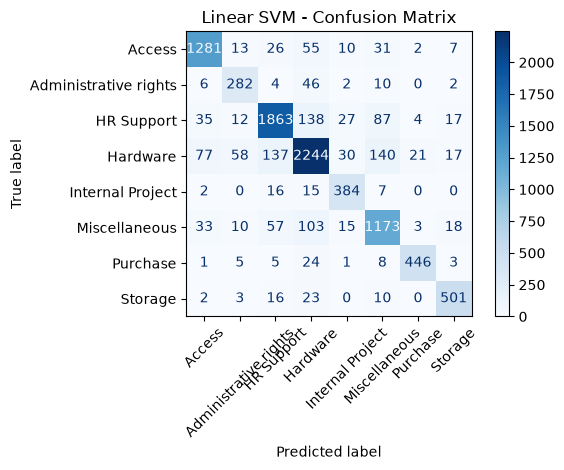

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, svm_predictions, labels=svm_model.classes_)

plt.figure(figsize=(12, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_model.classes_
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Linear SVM - Confusion Matrix")
plt.tight_layout()
plt.show()

In [27]:
import os
import joblib

os.makedirs(r"D:\FUTURE_ML_02\models", exist_ok=True)

joblib.dump(svm_model, r"D:\FUTURE_ML_02\models\linear_svm_model.pkl")
joblib.dump(tfidf, r"D:\FUTURE_ML_02\models\tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("TF-IDF Vectorizer saved successfully!")

Model saved successfully!
TF-IDF Vectorizer saved successfully!


## Ticket Priority Classification

A rule-based priority classification system is implemented to assign High, Medium, or Low priority to incoming IT support tickets based on urgency-related keywords and phrases.

Since the selected dataset does not contain priority labels, this component uses predefined rules rather than supervised machine learning.

In [28]:
import re

def assign_priority(ticket_text):
    text = ticket_text.lower()

    high_priority_keywords = [
        "critical", "urgent", "emergency", "system down",
        "server down", "complete outage", "security breach",
        "data breach", "unable to work", "production down"
    ]

    medium_priority_keywords = [
        "not working", "error", "failed", "failure",
        "unable to access", "access denied", "issue",
        "problem", "intermittent", "slow"
    ]

    if any(keyword in text for keyword in high_priority_keywords):
        return "High"

    elif any(keyword in text for keyword in medium_priority_keywords):
        return "Medium"

    else:
        return "Low"

In [29]:
test_tickets = [
    "Production server is down and all employees are unable to work",
    "Unable to access the company portal due to an error",
    "Request for installation of Microsoft Office",
    "Critical security breach detected in the system",
    "The application is running slowly"
]

for ticket in test_tickets:
    priority = assign_priority(ticket)
    print("Ticket:", ticket)
    print("Assigned Priority:", priority)
    print("-" * 80)

Ticket: Production server is down and all employees are unable to work
Assigned Priority: High
--------------------------------------------------------------------------------
Ticket: Unable to access the company portal due to an error
Assigned Priority: Medium
--------------------------------------------------------------------------------
Ticket: Request for installation of Microsoft Office
Assigned Priority: Low
--------------------------------------------------------------------------------
Ticket: Critical security breach detected in the system
Assigned Priority: High
--------------------------------------------------------------------------------
Ticket: The application is running slowly
Assigned Priority: Medium
--------------------------------------------------------------------------------


In [30]:
def classify_ticket(ticket_text):
    cleaned_ticket = clean_text(ticket_text)
    ticket_vector = tfidf.transform([cleaned_ticket])

    predicted_category = svm_model.predict(ticket_vector)[0]
    predicted_priority = assign_priority(ticket_text)

    return {
        "Ticket": ticket_text,
        "Predicted Category": predicted_category,
        "Assigned Priority": predicted_priority
    }

sample_ticket = "Unable to access the company server. The application shows an error."

result = classify_ticket(sample_ticket)

for key, value in result.items():
    print(f"{key}: {value}")

Ticket: Unable to access the company server. The application shows an error.
Predicted Category: Hardware
Assigned Priority: Medium


In [31]:
import pandas as pd

tickets = [
    "Production server is down and employees cannot work.",
    "Unable to access the company portal.",
    "Request for installation of Microsoft Office.",
    "Critical security breach detected in the system.",
    "The application is running slowly.",
    "Unable to access shared network folder.",
    "New employee needs an account setup.",
    "Laptop keyboard is not working.",
    "Request for additional storage space.",
    "Purchase approval required for new equipment."
]

large_df = pd.DataFrame({
    "Document": tickets * 10
})

large_df.to_csv(
    r"D:\FUTURE_ML_02\data\raw\large_test_tickets.csv",
    index=False
)

print("File created successfully!")
print("Total tickets:", len(large_df))

File created successfully!
Total tickets: 100
